### Javier Carballal Morgade
### Claudia Reyero Bardelás

# Bernstein-Vazirani algorithm

The Bernstein-Vazirani problem asks us to find a hidden binary string $s$ using access to a black-box function. The oracle computes

$$f(x) = s \cdot x \pmod 2$$

A classical deterministic algorithm can query the unit vectors to learn one bit of $s$ at a time, requiring $n$ oracle queries. The quantum algorithm uses one oracle query: it encodes all values of $f(x)$ as phases and uses interference to recover the complete string. Its quantum query complexity is therefore $O(1)$ instead of the classical $O(n)$.

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

## Choosing the hidden string

This is the string that the quantum circuit must discover.

For `1011`, the function is $f(x)=x_3 \oplus x_1 \oplus x_0$: only positions containing a 1 in the secret contribute to the parity.

In [2]:
secret_key = "1011"
n = len(secret_key)

## The oracle

The reversible quantum oracle uses an input register $|x\rangle$ and an auxiliary output qubit $|y\rangle$. Its action is

$$U_f|x\rangle|y\rangle=|x\rangle|y\oplus f(x)\rangle.$$

For every 1 in $s$, a CNOT adds the corresponding input bit to the auxiliary qubit modulo 2. Together, these gates compute $f(x)=s\cdot x$.

Qiskit numbers qubits from the least-significant bit, while strings are written most-significant bit first. We therefore reverse the string when mapping its bits to qubits.

Oracle circuit:


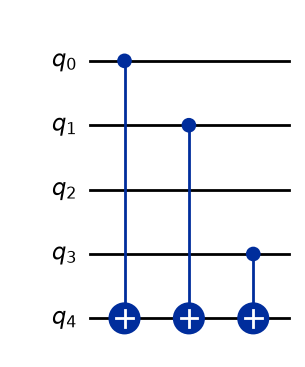

In [3]:
def make_oracle(secret_key):
    n = len(secret_key)
    oracle = QuantumCircuit(n + 1, name="U_f") # n qubits for the input and 1 ancilla qubit

    for qubit, bit in enumerate(reversed(secret_key)):
        if bit == "1":
            oracle.cx(qubit, n) # The ancilla qubit is qubit n

    return oracle.to_gate(label="U_f")


oracle_gate = make_oracle(secret_key)

print("Oracle circuit:")
display(oracle_gate.definition.draw("mpl"))

## The circuit

### Initial state

The initial state for this algorithm contains a uniform superposition of every possible $x$ for the input qubits and the $|{-}\rangle$ state for the ancilla qubit, preparing it for phase kickback.

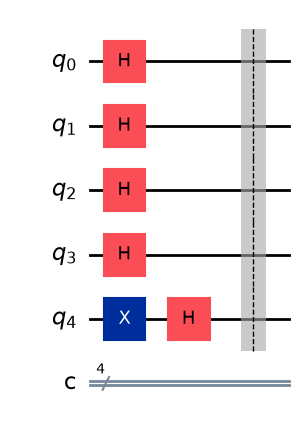

In [4]:
qc = QuantumCircuit(n + 1, n) # n qubits for the input and 1 ancilla qubit. n classical bits for the output

qc.x(n) # The ancilla qubit is qubit n, the last of the qc
qc.h(range(n + 1))
qc.barrier()

display(qc.draw("mpl"))

### Append the oracle gate

The oracle has the same qubit order as the main circuit, so we append it to all its qubits.

Because $X|{-}\rangle=-|{-}\rangle$, writing $f(x)$ into the auxiliary qubit produces phase kickback:

$$U_f|x\rangle|{-}\rangle=(-1)^{f(x)}|x\rangle|{-}\rangle.$$

Since $f(x)=s\cdot x$, the input register becomes

$$\frac{1}{\sqrt{2^n}}\sum_x(-1)^{s\cdot x}|x\rangle.$$

The auxiliary qubit is no longer needed; all useful information is now stored in the relative phases of the input amplitudes.

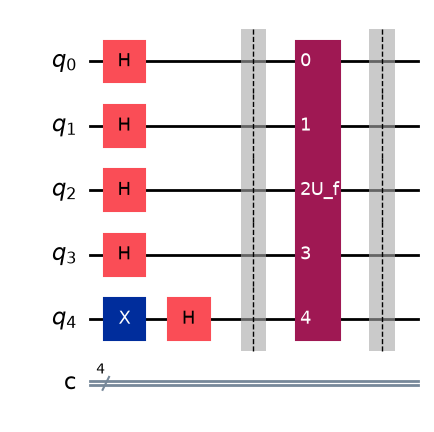

In [5]:
qc.append(oracle_gate, range(n + 1))
qc.barrier();

display(qc.draw("mpl"))

### Measurement

The second Hadamard layer converts the oracle's phase pattern into a computational-basis result. Using

$$H^{\otimes n}|x\rangle=\frac{1}{\sqrt{2^n}}\sum_y(-1)^{x\cdot y}|y\rangle,$$

the amplitude of $|y\rangle$ is proportional to

$$\sum_x(-1)^{s\cdot x}(-1)^{x\cdot y}=\sum_x(-1)^{x\cdot(s\oplus y)}.$$

The positive and negative terms cancel for every $y\ne s$. For $y=s$, every term equals $+1$, so the input register becomes exactly $|s\rangle$.

Final Circuit:


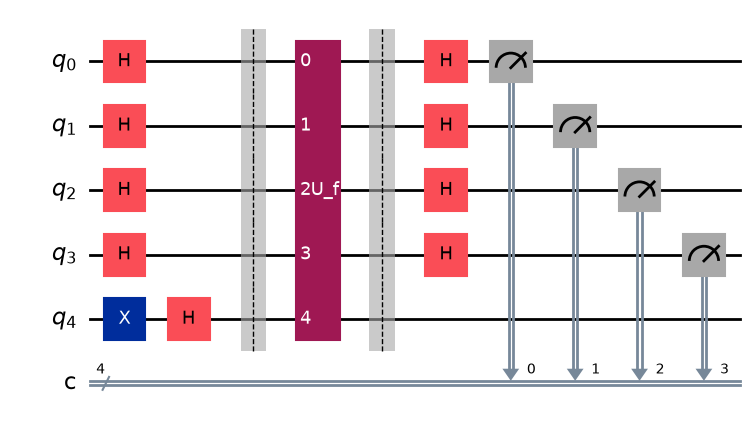

Circuit with the oracle decomposed:


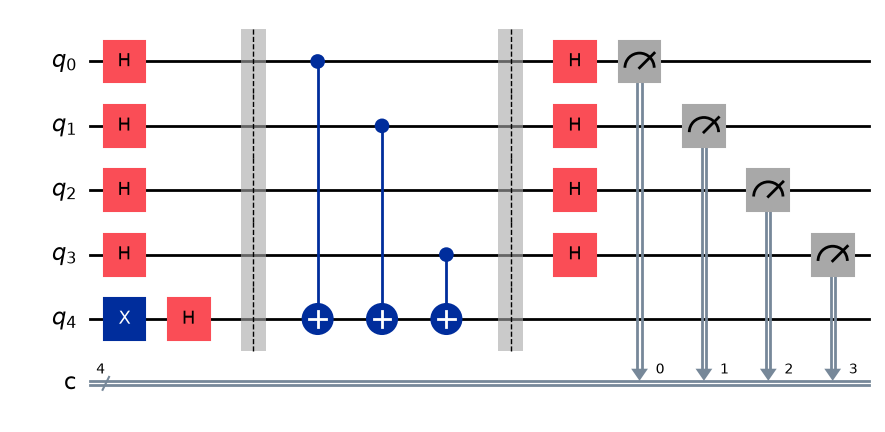

In [6]:
qc.h(range(n))
qc.measure(range(n), range(n))

print("Final Circuit:")
display(qc.draw("mpl"))

print("Circuit with the oracle decomposed:")
display(qc.decompose(gates_to_decompose=["U_f"]).draw("mpl"))

## Run the circuit

Since the output of the circuit should be deterministic in a noiseless simulator, all the shots should yield the same result (the secret key).

Measurement results: {'1011': 1024}


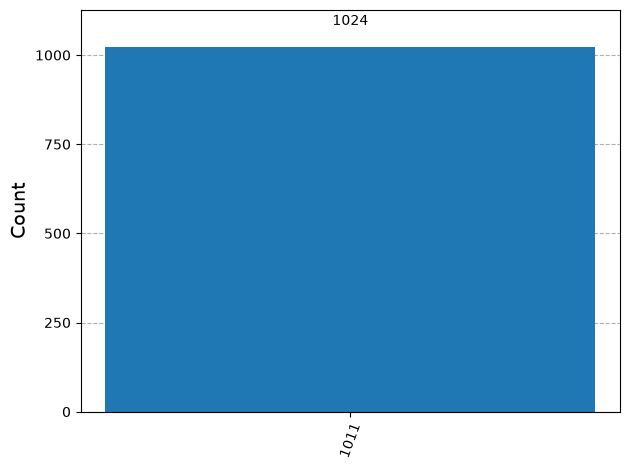

In [7]:
simulator = AerSimulator()
compiled_circuit = transpile(qc, simulator)
result = simulator.run(compiled_circuit, shots=1024).result()
counts = result.get_counts()

print("Measurement results:", counts)
plot_histogram(counts)

## Trying other secret keys

The following code is a compact version of the algorithm used for testing different keys. It uses only one shot because the output is deterministic in the noiseless simulator.

In [8]:
def bv_circuit(secret_key):
    n = len(secret_key)
    circuit = QuantumCircuit(n + 1, n)

    # Prepare the input superposition and the ancilla in |->.
    circuit.x(n)
    circuit.h(range(n + 1))

    # Query to the oracle gate.
    circuit.append(make_oracle(secret_key), range(n + 1))

    # Convert the phase pattern into the secret key and measure it.
    circuit.h(range(n))
    circuit.measure(range(n), range(n))
    return circuit


test_keys = ["0", "1", "00", "10", "11", "0101", "1111", "100101", "10011110110"]

for key in test_keys:
    qc = bv_circuit(key)
    compiled = transpile(qc, simulator)
    counts = simulator.run(compiled, shots=1).result().get_counts()
    found = max(counts, key=counts.get)
    print(f"secret = {key:>6} \t result = {found:>6} \t correct = {found == key}")
    assert found == key

secret =      0 	 result =      0 	 correct = True
secret =      1 	 result =      1 	 correct = True
secret =     00 	 result =     00 	 correct = True
secret =     10 	 result =     10 	 correct = True
secret =     11 	 result =     11 	 correct = True
secret =   0101 	 result =   0101 	 correct = True
secret =   1111 	 result =   1111 	 correct = True
secret = 100101 	 result = 100101 	 correct = True
secret = 10011110110 	 result = 10011110110 	 correct = True
